In [26]:
import re
import csv
import calendar
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

from pathlib import Path

# Lokasi folder data curah hujan
FOLDER_DATA = Path(r"D:\semester 4\Magang\datacurahhujan")
FILE_DATA = FOLDER_DATA / "CURAH HUJAN STAMET PALU 2020.txt"

# Folder untuk menyimpan hasil pengolahan
FOLDER_OUTPUT = FOLDER_DATA / "output_curah_hujan_2020"
FOLDER_OUTPUT.mkdir(parents=True, exist_ok=True)

if not FILE_DATA.exists():
    print("File tidak ditemukan!")
    print("File TXT yang tersedia di folder:")
    for file in FOLDER_DATA.iterdir():
        print(file.name)
else:
    print("File input ditemukan:", FILE_DATA)
    print("Folder hasil:", FOLDER_OUTPUT)

teks = None
for encoding in ("utf-8", "cp1252", "latin-1"):
    try:
        teks = FILE_DATA.read_text(encoding=encoding)
        print("Encoding yang digunakan:", encoding)
        break
    except UnicodeDecodeError:
        continue

if teks is None:
    raise UnicodeError("File tidak dapat dibaca dengan encoding yang dicoba.")

baris_file = teks.splitlines()
indeks_header = None

for i, baris in enumerate(baris_file):
    if "BLN" in baris.upper() and "JAN" in baris.upper() and "FEB" in baris.upper():
        indeks_header = i
        break

if indeks_header is None:
    raise ValueError("Baris header bulan (BLN/TGL, JAN, FEB, ...) tidak ditemukan.")

baris_header = next(csv.reader([baris_file[indeks_header]], delimiter="\t"))
print("Baris header:", baris_header)
print("Contoh baris data:", baris_file[indeks_header + 1])

bulan_sumber = ["JAN", "FEB", "MAR", "APR", "MEI", "JUN",
                "JUL", "AGT", "SEP", "OKT", "NOP", "DES"]
nama_bulan = ["Januari", "Februari", "Maret", "April", "Mei", "Juni",
              "Juli", "Agustus", "September", "Oktober", "November", "Desember"]

data_harian = []
jumlah_resmi = {}
hh_sumber = {}

for baris in baris_file[indeks_header + 1:]:
    if not baris.strip():
        continue
    kolom = next(csv.reader([baris], delimiter="\t"))
    kolom = [x.strip() for x in kolom]

    if not kolom or not kolom[0]:
        continue

    label = kolom[0].upper()

    # Baris JUMLAH dan HH disimpan terpisah untuk pembanding.
    if label.startswith("JUMLAH"):
        nilai = kolom[1:13]
        jumlah_resmi = {
            nama_bulan[j]: pd.to_numeric(nilai[j] if j < len(nilai) else None, errors="coerce")
            for j in range(12)
        }
        continue

    if label == "HH":
        nilai = kolom[1:13]
        hh_sumber = {
            nama_bulan[j]: pd.to_numeric(nilai[j] if j < len(nilai) else None, errors="coerce")
            for j in range(12)
        }
        continue

    if not re.fullmatch(r"\d{1,2}", label):
        continue

    tanggal = int(label)
    if not 1 <= tanggal <= 31:
        continue

    nilai_harian = kolom[1:13]
    for j, bulan in enumerate(nama_bulan):
        if tanggal > calendar.monthrange(2020, j + 1)[1]:
            continue
        teks_nilai = nilai_harian[j].strip() if j < len(nilai_harian) else ""
        angka = pd.to_numeric(teks_nilai, errors="coerce") if teks_nilai not in ("", "-") else np.nan
        data_harian.append({
            "Tanggal": pd.Timestamp(year=2020, month=j + 1, day=tanggal),
            "Hari": tanggal,
            "Bulan": bulan,
            "Bulan_ke": j + 1,
            "Curah_Hujan_mm": angka,
            "Teks_Asli": teks_nilai
        })

df = pd.DataFrame(data_harian)
df = df.sort_values("Tanggal").reset_index(drop=True)

print("Jumlah baris tanggal-bulan:", len(df))
print("Rentang tanggal:", df["Tanggal"].min(), "sampai", df["Tanggal"].max())
display(df.head(12))

File input ditemukan: D:\semester 4\Magang\datacurahhujan\CURAH HUJAN STAMET PALU 2020.txt
Folder hasil: D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020
Encoding yang digunakan: cp1252
Baris header: ['BLN / TGL', 'JAN', 'FEB', 'MAR', 'APR', 'MEI', 'JUN', 'JUL', 'AGT', 'SEP', 'OKT', 'NOP', 'DES', '']
Contoh baris data: 													
Jumlah baris tanggal-bulan: 366
Rentang tanggal: 2020-01-01 00:00:00 sampai 2020-12-31 00:00:00


,Tanggal,Hari,Bulan,Bulan_ke,Curah_Hujan_mm,Teks_Asli
0,2020-01-01,1,Januari,1,0.0,0
1,2020-01-02,2,Januari,1,0.0,0
2,2020-01-03,3,Januari,1,10.0,10
3,2020-01-04,4,Januari,1,0.0,0
4,2020-01-05,5,Januari,1,NaN,-
5,2020-01-06,6,Januari,1,0.2,0.2
6,2020-01-07,7,Januari,1,1.1,1.1
7,2020-01-08,8,Januari,1,0.0,0
8,2020-01-09,9,Januari,1,NaN,-
9,2020-01-10,10,Januari,1,NaN,-


In [ ]:
from pathlib import Path

# Lokasi folder data curah hujan
FOLDER_DATA = Path(r"D:\semester 4\Magang\datacurahhujan")
FILE_DATA = FOLDER_DATA / "CURAH HUJAN STAMET PALU 2020.txt"

FOLDER_OUTPUT = FOLDER_DATA / "output_curah_hujan_2020"
FOLDER_OUTPUT.mkdir(parents=True, exist_ok=True)

if not FILE_DATA.exists():
    print("File tidak ditemukan!")
    print("File TXT yang tersedia di folder:")
    for file in FOLDER_DATA.iterdir():
        print(file.name)
else:
    print("File input ditemukan:", FILE_DATA)
    print("Folder hasil:", FOLDER_OUTPUT)

File input ditemukan: D:\semester 4\Magang\datacurahhujan\CURAH HUJAN STAMET PALU 2020.txt
Folder hasil: D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020


In [ ]:
teks = None
for encoding in ("utf-8", "cp1252", "latin-1"):
    try:
        teks = FILE_DATA.read_text(encoding=encoding)
        print("Encoding yang digunakan:", encoding)
        break
    except UnicodeDecodeError:
        continue

if teks is None:
    raise UnicodeError("File tidak dapat dibaca dengan encoding yang dicoba.")

baris_file = teks.splitlines()
indeks_header = None

for i, baris in enumerate(baris_file):
    if "BLN" in baris.upper() and "JAN" in baris.upper() and "FEB" in baris.upper():
        indeks_header = i
        break

if indeks_header is None:
    raise ValueError("Baris header bulan (BLN/TGL, JAN, FEB, ...) tidak ditemukan.")

baris_header = next(csv.reader([baris_file[indeks_header]], delimiter="\t"))
print("Baris header:", baris_header)
print("Contoh baris data:", baris_file[indeks_header + 1])

Encoding yang digunakan: cp1252
Baris header: ['BLN / TGL', 'JAN', 'FEB', 'MAR', 'APR', 'MEI', 'JUN', 'JUL', 'AGT', 'SEP', 'OKT', 'NOP', 'DES', '']
Contoh baris data: 													


## Pemeriksaan kualitas data (QA/QC)
Pemeriksaan ini menandai nilai hilang, nilai negatif, dan tanggal yang tidak sesuai kalender. Tidak ada nilai yang diimputasi atau dihapus dari tabel.

In [ ]:
jumlah_record = len(df)
jumlah_hilang = int(df["Curah_Hujan_mm"].isna().sum())
jumlah_negatif = int((df["Curah_Hujan_mm"] < 0).sum())
jumlah_duplikat_tanggal = int(df["Tanggal"].duplicated().sum())

ringkasan_qc = pd.DataFrame({
    "Pemeriksaan": [
        "Jumlah record tanggal-bulan",
        "Nilai curah hujan kosong/tanda '-'",
        "Nilai curah hujan negatif",
        "Tanggal duplikat"
    ],
    "Hasil": [
        jumlah_record, jumlah_hilang, jumlah_negatif, jumlah_duplikat_tanggal
    ]
})
display(ringkasan_qc)

print("Nilai curah hujan minimum (angka yang tersedia):", df["Curah_Hujan_mm"].min())
print("Nilai curah hujan maksimum (angka yang tersedia):", df["Curah_Hujan_mm"].max())

,Pemeriksaan,Hasil
0,Jumlah record tanggal-bulan,366
1,Nilai curah hujan kosong/tanda '-',116
2,Nilai curah hujan negatif,0
3,Tanggal duplikat,0


Nilai curah hujan minimum (angka yang tersedia): 0.0
Nilai curah hujan maksimum (angka yang tersedia): 55.9


## 10. Ringkasan curah hujan bulanan
Total hasil hitung notebook merupakan jumlah angka harian yang tersedia. Jika ada nilai hilang, total tersebut dapat lebih rendah dari nilai sebenarnya. Selisih dengan `JUMLAH` ditampilkan untuk audit, bukan langsung dianggap kesalahan.

In [28]:
ringkasan_bulanan = (
    df.groupby(["Bulan_ke", "Bulan"], sort=True)
      .agg(
          Total_hasil_hitung_mm=("Curah_Hujan_mm", "sum"),
          Hari_dengan_angka=("Curah_Hujan_mm", "count"),
          Hari_tanpa_angka=("Curah_Hujan_mm", lambda x: int(x.isna().sum())),
          Maksimum_harian_mm=("Curah_Hujan_mm", "max"),
          Rata_rata_harian_tersedia_mm=("Curah_Hujan_mm", "mean")
      )
      .reset_index()
)

ringkasan_bulanan["Jumlah_resmi_sumber_mm"] = ringkasan_bulanan["Bulan"].map(jumlah_resmi)
ringkasan_bulanan["Selisih_hitung_minus_sumber_mm"] = (
    ringkasan_bulanan["Total_hasil_hitung_mm"] - ringkasan_bulanan["Jumlah_resmi_sumber_mm"]
)
ringkasan_bulanan["HH_sumber"] = ringkasan_bulanan["Bulan"].map(hh_sumber)

display(ringkasan_bulanan.round(2))

,Bulan_ke,Bulan,Total_hasil_hitung_mm,Hari_dengan_angka,Hari_tanpa_angka,Maksimum_harian_mm,Rata_rata_harian_tersedia_mm,Jumlah_resmi_sumber_mm,Selisih_hitung_minus_sumber_mm,HH_sumber
0,1,Januari,14.7,11,20,10.0,1.34,14.7,0.0,11
1,2,Februari,25.4,15,14,21.2,1.69,25.4,0.0,15
2,3,Maret,38.1,16,15,25.5,2.38,38.1,0.0,16
3,4,April,63.9,16,14,27.0,3.99,63.9,0.0,16
4,5,Mei,49.7,26,5,19.2,1.91,49.7,0.0,26
5,6,Juni,88.9,26,4,15.8,3.42,88.9,0.0,26
6,7,Juli,181.3,25,6,34.8,7.25,181.3,-0.0,25
7,8,Agustus,58.5,25,6,13.7,2.34,58.5,0.0,25
8,9,September,304.4,28,2,55.9,10.87,304.4,0.0,28
9,10,Oktober,48.3,25,6,13.4,1.93,48.3,0.0,25


## Grafik akumulasi curah hujan bulanan

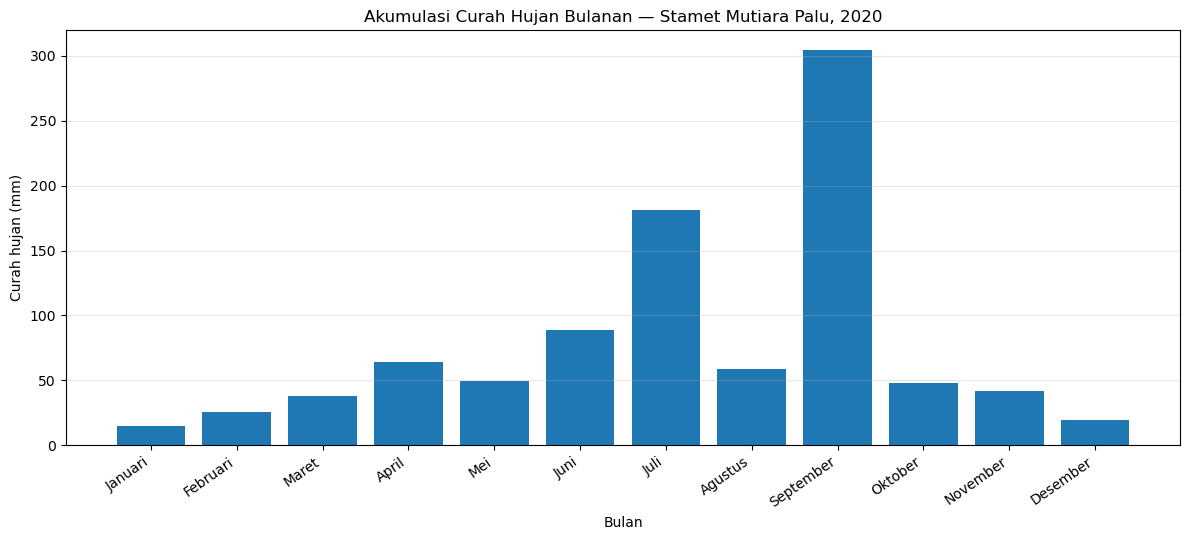

Grafik tersimpan: D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020\curah_hujan_bulanan_2020.png


In [ ]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(ringkasan_bulanan["Bulan"], ringkasan_bulanan["Total_hasil_hitung_mm"])
ax.set_title("Akumulasi Curah Hujan Bulanan — Stamet Mutiara Palu, 2020")
ax.set_xlabel("Bulan")
ax.set_ylabel("Curah hujan (mm)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
file_grafik = FOLDER_OUTPUT / "curah_hujan_bulanan_2020.png"
fig.savefig(file_grafik, dpi=300, bbox_inches="tight")
plt.show()
print("Grafik tersimpan:", file_grafik.resolve())

## Grafik curah hujan harian

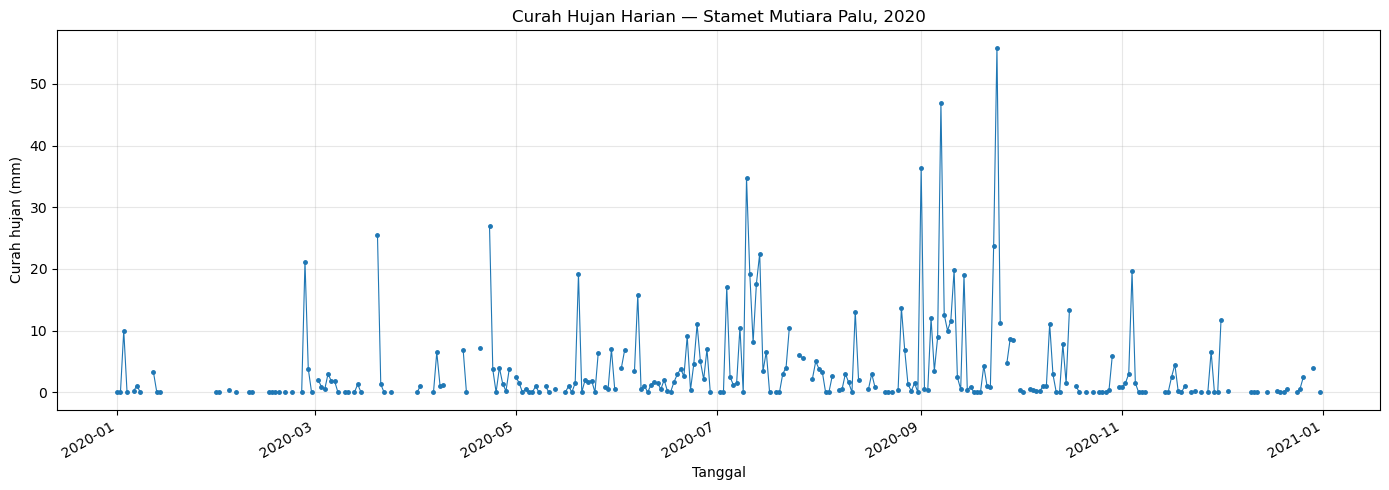

Grafik tersimpan: D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020\curah_hujan_harian_2020.png


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Tanggal"], df["Curah_Hujan_mm"], marker="o", markersize=2.5, linewidth=0.8)
ax.set_title("Curah Hujan Harian — Stamet Mutiara Palu, 2020")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Curah hujan (mm)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
file_grafik_harian = FOLDER_OUTPUT / "curah_hujan_harian_2020.png"
fig.savefig(file_grafik_harian, dpi=300, bbox_inches="tight")
plt.show()
print("Grafik tersimpan:", file_grafik_harian.resolve())

In [ ]:
hari_tertinggi = df.loc[df["Curah_Hujan_mm"].idxmax(), ["Tanggal", "Bulan", "Curah_Hujan_mm"]]
print("Tanggal dengan curah hujan terbesar yang tercatat:")
display(hari_tertinggi.to_frame(name="Nilai"))

Tanggal dengan curah hujan terbesar yang tercatat:


,Nilai
Tanggal,2020-09-24 00:00:00
Bulan,September
Curah_Hujan_mm,55.9


In [ ]:
file_harian_csv = FOLDER_OUTPUT / "data_harian_curah_hujan_2020.csv"
file_bulanan_csv = FOLDER_OUTPUT / "ringkasan_bulanan_curah_hujan_2020.csv"
file_qc_csv = FOLDER_OUTPUT / "laporan_qc_curah_hujan_2020.csv"

df.to_csv(file_harian_csv, index=False, encoding="utf-8-sig")
ringkasan_bulanan.to_csv(file_bulanan_csv, index=False, encoding="utf-8-sig")
ringkasan_qc.to_csv(file_qc_csv, index=False, encoding="utf-8-sig")

print("File yang dibuat:")
for file in [file_harian_csv, file_bulanan_csv, file_qc_csv, file_grafik, file_grafik_harian]:
    print("-", file.resolve())

File yang dibuat:
- D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020\data_harian_curah_hujan_2020.csv
- D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020\ringkasan_bulanan_curah_hujan_2020.csv
- D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020\laporan_qc_curah_hujan_2020.csv
- D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020\curah_hujan_bulanan_2020.png
- D:\semester 4\Magang\datacurahhujan\output_curah_hujan_2020\curah_hujan_harian_2020.png
